# Ideal-point comparisons with GTUM

When does a statement best match a person's trait level? Fit the generalized
Thurstonian unfolding model (GTUM) to 100 simulated respondents across
24 triplets.

## Model preferences by distance

Let $p$ index respondents and $j,k$ the two statements in a comparison
from block $b$. The utility of $j$ depends on how close the respondent's
score $\theta_{p,t(j)}$ is to the statement's ideal point $\delta_j$:

$$
m_{pj}=-a_j\left|\theta_{p,t(j)}-\delta_j\right|.
$$

The utility is highest at the ideal point, where the distance is zero.
The positive loading $a_j$ controls how quickly it falls as the respondent
moves away in either direction.

The response $Y_{pbjk}=1$ favors the first statement $j$. Define the
comparison contrast $D_{pbjk}$ and convert it to a probability:

$$
D_{pbjk}=m_{pj}-m_{pk}-\gamma_{bjk},\qquad
P(Y_{pbjk}=1)=\frac{1}{1+e^{-D_{pbjk}}}.
$$

The pair threshold $\gamma_{bjk}$ measures how much greater the utility
of $j$ must be for the two answers to be equally likely. If the utility
difference exceeds the threshold, the respondent is more likely to
choose $j$. This fit uses the standard logistic link with no person–block
effect. Each recorded comparison contributes one Bernoulli factor.

### Set the score scale

Each trait has mean zero and SD one. The design declares the signs of
signed ideal points. Trait correlations are estimated.
[GTUM model and priors](../models/gtum.md)

## Read the design and responses

The design assigns each statement to a trait and specifies its
`location_side`. A negative or positive side constrains the ideal point
to that half of the trait scale. Zero leaves its sign free.

In [1]:
import pandas as pd
import seaborn as sns

import pyfcirt as fc

sns.set_theme(style="ticks")

study = fc.load_example("simulated_gtum", model="GTUM", n_persons=100)
study.data.design.head(3)

,block_id,position,statement_id,trait,keying,location_side
0,B1,1,S1,theta1,1,-1
1,B1,2,S2,theta2,1,-1
2,B1,3,S3,theta3,1,-1


Each row names two statements from one block. A response of 1 favors
the first statement. A response of 0 favors the second. These data contain
7,200 binary comparisons across 2,400 person–block records. People rated
the comparisons separately, so their choices need not form a ranking.

In [2]:
study.data.responses.frame.head(3)

,person_id,block_id,statement_1,statement_2,response,status
0,1,B1,S1,S2,1,answered
1,1,B1,S1,S3,1,answered
2,1,B1,S2,S3,0,answered


## Check the prior for one comparison

Compare the prior-predicted preference rate for S1 over S2 with the observed
83 out of 100. The histogram shows variation implied by the priors before
conditioning on answers. The marker shows the observed rate.

In [3]:
model = fc.Model()
model.add_fc(
    study.data.design,
    study.data.responses.frame,
    format="comparison_long",
    model="GTUM",
)
model.prepare()
print(model.summary())

Model: GTUM
100 people, 4 traits, 24 blocks, 72 statements
Observations: 7,200 pair comparisons
Measurements:
  rank: 24 blocks, size=3, link=logit
Population:
  theta ~ MvNormal(mu=0, cov=R)
  R [4 x 4] ~ LKJCorr(n=4, eta=1)
Priors:
    loading [72] ~ LogNormal(mu=0, sigma=0.5)
    location (location_negative) [36] ~ TruncatedNormal(mu=-2, sigma=1, lower=-inf, upper=0)
    location (location_positive) [36] ~ TruncatedNormal(mu=2, sigma=1, lower=0, upper=inf)
    cutpoint [72] ~ Normal(mu=0, sigma=1)


The summary lists statement-pair observations and separate priors for positive and negative locations.

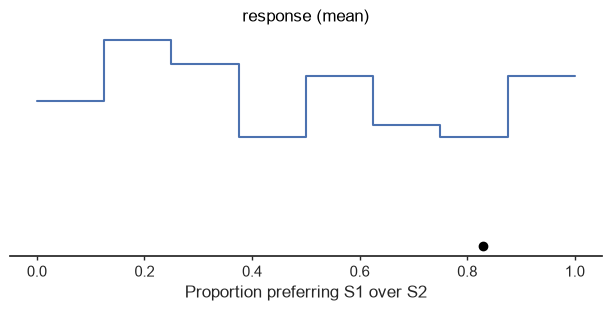

In [4]:
import arviz_plots as azp
import matplotlib.pyplot as plt

prior = model.prior_predictive(draws=100, random_seed=48)
design = model.prepared.constant_data
first = design.statement_label.isel(statement=design.pair_statement_1)
second = design.statement_label.isel(statement=design.pair_statement_2)
selected_pair = (first == "S1") & (second == "S2")
pair = design.pair.where(selected_pair, drop=True).item()
pair_obs = design.obs.where(design.obs_pair == pair, drop=True)
view = fc.predictive_view(prior, block="B1").sel(obs=pair_obs)
azp.plot_ppc_tstat(
    view,
    group="prior_predictive",
    t_stat="mean",
    kind="hist",
    visuals={"observed_tstat": {}},
    backend="matplotlib",
    figure_kwargs={"figsize": (6, 3), "layout": "constrained"},
)
plt.gca().set_xlabel("Proportion preferring S1 over S2")
plt.show()

## Fit the model

The displayed estimates use four chains with 1,000 warmup
iterations and 1,000 retained draws per chain. [Estimation backend setup](../examples/estimation_backends.md)

In [5]:
model.fit(draws=1000, tune=1000, chains=4);

The maximum R-hat is 1.006, and the minimum bulk and tail effective sample
sizes are 439 and 819. There are zero divergences. The rank and density
panels examine the two scores of respondent 1.

In [6]:
import arviz as az
import numpy as np

posterior = model.idata.posterior.to_dataset().reset_coords(drop=True)
with np.errstate(invalid="ignore", divide="ignore"):
    r_hat = az.rhat(posterior).max().to_array().max().item()
    bulk = az.ess(posterior, method="bulk").min().to_array().min().item()
    tail = az.ess(posterior, method="tail").min().to_array().min().item()

print(f"Max R-hat: {r_hat:.3f}")
print(f"Min bulk / tail ESS: {bulk:.0f} / {tail:.0f}")
print("Divergences:", int(model.idata.sample_stats.diverging.sum()))

Max R-hat: 1.006
Min bulk / tail ESS: 439 / 819
Divergences: 0


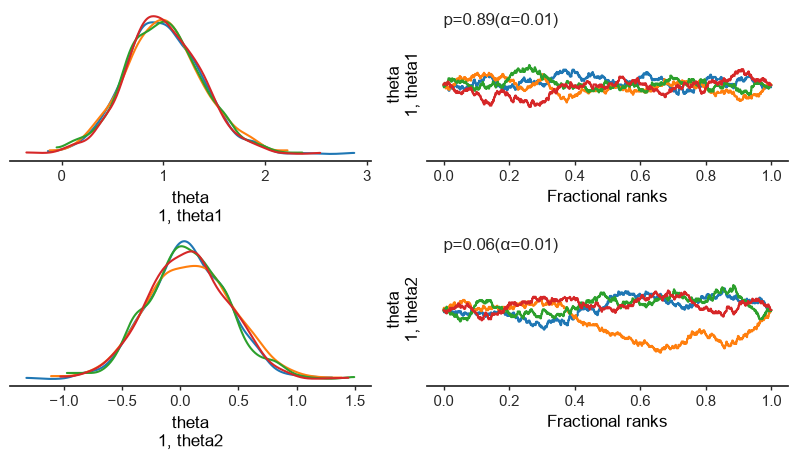

In [7]:
with sns.color_palette("tab10"):
    azp.plot_rank_dist(
        model.idata,
        var_names=["theta"],
        coords={"person": [1], "trait": ["theta1", "theta2"]},
        compact=False,
        backend="matplotlib",
        figure_kwargs={"figsize": (8, 4.5), "layout": "constrained"},
    )
    plt.show()

## Read the ideal-point estimates

Read locations in standardized trait units. The HDI columns show a 95%
highest-density interval for each ideal point. The negative location of
S1 follows its design restriction, and the interval shows uncertainty
about where on that side the ideal point lies.

In [8]:
locations = model.coef(var_names="location", kind="stats")
table = locations.reset_index().set_index("statement")
columns = ["trait", "mean", "sd", "hdi95_lb", "hdi95_ub"]
table.loc[["S1", "S13", "S25"], columns].round(2)

,trait,mean,sd,hdi95_lb,hdi95_ub
statement,,,,,
S1,theta1,-1.70,0.61,-2.90,-0.60
S13,theta1,2.24,0.82,0.95,3.78
S25,theta1,-1.39,0.36,-2.10,-0.76


The lines show four expected statement utilities at the posterior mean
loadings and locations. Each line peaks at its ideal point. The bottom
marks and gray band show the distribution and middle 90% of respondents'
posterior mean scores on the first trait.

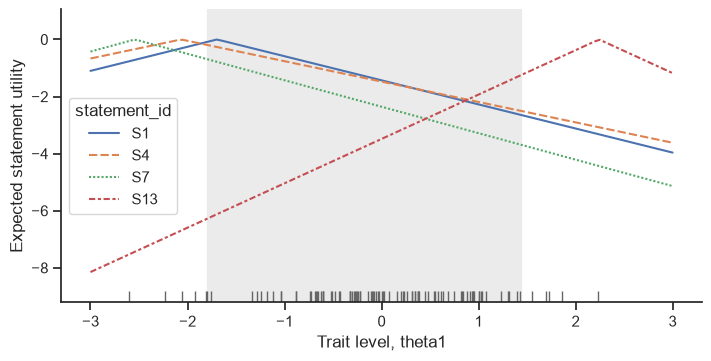

In [9]:
import jax.numpy as jnp

statements = study.data.design.query("trait == 'theta1'")
statements = statements.statement_id.drop_duplicates().head(4)
estimates = model.coef(
    var_names=["loading", "location"],
    kind="stats",
).reset_index()
point = estimates.pivot(index="statement", columns="parameter", values="mean").loc[statements]

theta_grid = jnp.linspace(-3, 3, 121)
a = jnp.asarray(point.loading.to_numpy())
delta = jnp.asarray(point.location.to_numpy())
utility = -a * jnp.abs(theta_grid[:, None] - delta)
curves = pd.DataFrame(utility, index=theta_grid, columns=statements)
scores = model.idata.posterior.theta.sel(trait="theta1").mean(("chain", "draw"))
low, high = scores.quantile([0.05, 0.95]).values

fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.axvspan(low, high, color="0.92")
sns.lineplot(data=curves, ax=ax)
sns.rugplot(x=scores.values, height=0.04, color="0.4", ax=ax)
ax.set(xlabel="Trait level, theta1", ylabel="Expected statement utility")
sns.despine(fig=fig)
plt.show()

## Check the response predictions

Use the same S1 versus S2 comparison as in the prior check. The calibration
curve compares the predicted probability of preferring S1 with the observed
frequency. The dashed diagonal marks agreement.

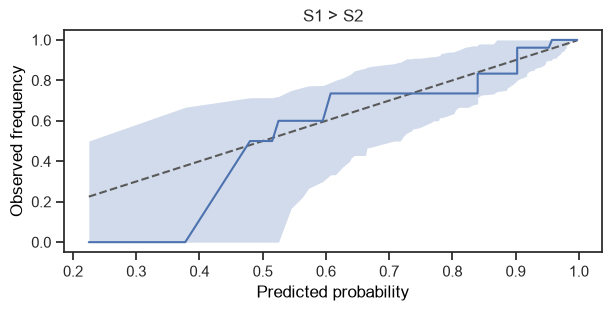

In [10]:
predictions = model.posterior_predictive(draws=400, random_seed=49)
view = fc.predictive_view(predictions, block="B1").sel(obs=pair_obs)
azp.plot_ppc_pava(
    view,
    data_type="binary",
    backend="matplotlib",
    figure_kwargs={"figsize": (6, 3), "layout": "constrained"},
)
plt.gca().set(
    title="S1 > S2",
    xlabel="Predicted probability",
    ylabel="Observed frequency",
)
plt.show()

The Pearson check uses the recorded comparisons to assess overall fit.
The posterior predictive p-value (PPP) is the share of replicated
discrepancies at least as large as the observed one.

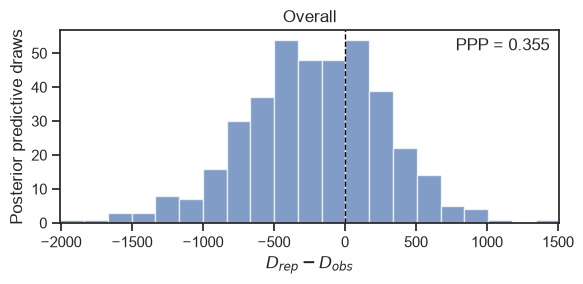

In [11]:
overall = model.chi_ppp(predictions=predictions)
fc.plot_ppp(overall, quantile_range=(0.005, 0.995), figsize=(6, 3))
plt.show()

To inspect local fit, group the same discrepancy check by comparison
pair within B1. Each row uses 100 observed answers.

In [12]:
pair_checks = model.chi_ppp(predictions=predictions, blocks=["B1"], groupby="pair", store=False)
pair_table = pair_checks[["PPP", "n_obs"]].to_dataframe().set_index(["statement_1", "statement_2"])
pair_table[["PPP", "n_obs"]].round({"PPP": 3})

PPP  n_obs
statement_1 statement_2              
S1          S2           0.265    100
            S3           0.878    100
S2          S3           0.672    100

## Read score precision

The ridges show the first two trait scores for respondents 1, 2 and 3.
The markers show posterior means and the lines show 50% and 95% intervals.
Compare the widths before interpreting differences between respondents.

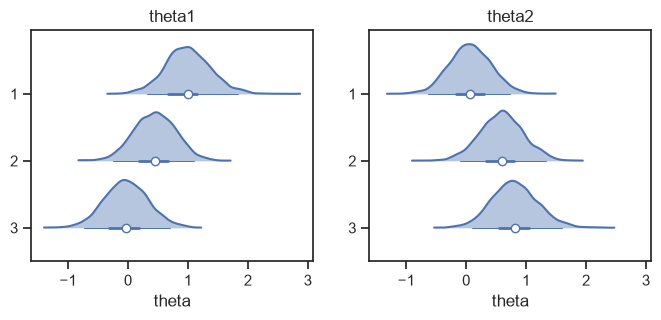

In [13]:
fc.plot_ridge(
    model.idata,
    coords={"person": [1, 2, 3], "trait": ["theta1", "theta2"]},
    max_rows=3,
    col_wrap=2,
    figsize=(8, 3),
)
plt.show()

Empirical reliability summarizes how well the estimated scores distinguish
respondents on each trait, relative to their posterior uncertainty.

In [14]:
reliability = model.reliability()["reliability"].to_series()
reliability.round(3).to_frame("Reliability")

,Reliability
trait,
theta1,0.847
theta2,0.838
theta3,0.787
theta4,0.828


## References

Zhang, B., Tu, N., Angrave, L., Zhang, S., Sun, T., Tay, L., & Li, J. (2024). The generalized Thurstonian unfolding model (GTUM): Advancing the modeling of forced-choice data. *Organizational Research Methods, 27*(4), 713–747. [https://doi.org/10.1177/10944281231210481](https://doi.org/10.1177/10944281231210481).
